# Qwen2-VL Diagram Adapter Demo

This notebook loads the Qwen2-VL base model plus the LoRA adapter saved by `src/train/train_qwen.py`, samples processed diagram images, and compares model generations with the supervised targets.

In [1]:
import json
import random
from pathlib import Path

import torch
import yaml
from IPython.display import Markdown, display
from PIL import Image


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "src" / "train" / "config.yaml").exists():
            return path
    raise FileNotFoundError(f"Could not find src/train/config.yaml from {start}")


PROJECT_ROOT = find_repo_root()
CONFIG_PATH = PROJECT_ROOT / "src" / "train" / "config.yaml"
cfg = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))

BASE_MODEL = Path(cfg["model"]["path"])
ADAPTER_DIR = Path(cfg["train"]["output_dir"])
PROCESSED_DIR = Path(cfg["data"]["processed_dir"])

for label, path in {
    "base model": BASE_MODEL,
    "trained adapter": ADAPTER_DIR,
    "processed data": PROCESSED_DIR,
}.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {label}: {path}")

if not (ADAPTER_DIR / "adapter_config.json").exists():
    raise FileNotFoundError(f"No LoRA adapter_config.json found in {ADAPTER_DIR}")

print(f"Project root:   {PROJECT_ROOT}")
print(f"Base model:     {BASE_MODEL}")
print(f"Adapter:        {ADAPTER_DIR}")
print(f"Processed data: {PROCESSED_DIR}")
print(f"CUDA available: {torch.cuda.is_available()}")

Project root:   D:\src\Diagram_extraction
Base model:     D:\data\diagram_extraction\models\base\Qwen__Qwen2-VL-2B-Instruct
Adapter:        D:\data\diagram_extraction\runs\qwen2vl-2b-diagram-lora
Processed data: D:\data\diagram_extraction\processed
CUDA available: True


## Pick Sample Images

By default this uses test-set `diagram_to_graph` examples, because that is the core task you trained for. Change `TASK`, `SPLIT`, or `SOURCE` to inspect other parts of the processed dataset.

In [2]:
def read_jsonl(path: Path) -> list[dict]:
    rows = []
    with path.open(encoding="utf-8") as fh:
        for line in fh:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows


def usable_rows(split: str, task: str | None = None, source: str | None = None) -> list[dict]:
    path = PROCESSED_DIR / f"{split}.jsonl"
    rows = []
    for row in read_jsonl(path):
        image_path = row.get("image_path")
        if not image_path or not (PROCESSED_DIR / image_path).exists():
            continue
        if task and row.get("task") != task:
            continue
        if source and row.get("source_dataset") != source:
            continue
        rows.append(row)
    return rows


TASK = "diagram_to_graph"
SPLIT = "test"
SOURCE = None  # Example: "mermaid_flowchart_transformer", "vgqa", "diagramgen", "ai2d_caption"
NUM_SAMPLES = 5
RANDOM_SEED = 7

rows = usable_rows(SPLIT, task=TASK, source=SOURCE)
if not rows:
    for fallback_split in ("val", "train"):
        rows = usable_rows(fallback_split, task=TASK, source=SOURCE)
        if rows:
            SPLIT = fallback_split
            break

rng = random.Random(RANDOM_SEED)
rng.shuffle(rows)
samples = rows[:NUM_SAMPLES]

print(f"Selected {len(samples)} samples from split={SPLIT!r}, task={TASK!r}, source={SOURCE!r}")
for i, row in enumerate(samples):
    print(
        f"[{i}] id={row['id']} | source={row['source_dataset']} | "
        f"format={row['target_format']} | image={row['image_path']}"
    )

Selected 5 samples from split='test', task='diagram_to_graph', source=None
[0] id=rakitha-test-6038_gaussian | source=mermaid_flowchart_transformer | format=mermaid | image=images/rakitha/test/6038_gaussian.jpg
[1] id=rakitha-test-1012_Automobile Manufacturing | source=mermaid_flowchart_transformer | format=mermaid | image=images/rakitha/test/1012_Automobile Manufacturing.jpg
[2] id=rakitha-test-6043 | source=mermaid_flowchart_transformer | format=mermaid | image=images/rakitha/test/6043.jpg
[3] id=rakitha-test-1048_HR | source=mermaid_flowchart_transformer | format=mermaid | image=images/rakitha/test/1048_HR.jpg
[4] id=rakitha-test-1002_Health Care | source=mermaid_flowchart_transformer | format=mermaid | image=images/rakitha/test/1002_Health Care.jpg


### rakitha-test-6038_gaussian
source: `mermaid_flowchart_transformer` | task: `diagram_to_graph` | format: `mermaid`

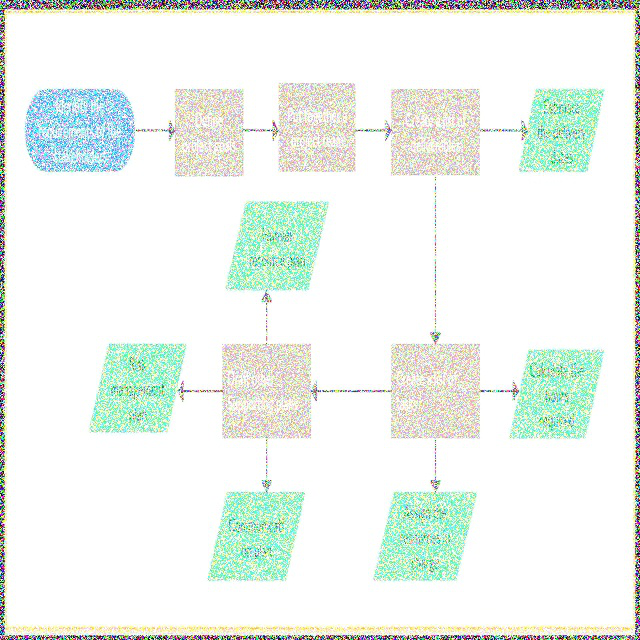

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

TARGET:
flowchart TB
    A([Identify the requirements of the stakeholders]) --> B[Define project goals]
    B --> C[Put together a project team]
    C --> E[Create a list of deliverables]
    E --> F[/Estimate the delivery dates/]
    E --> G[Create a list of tasks]
    G --> H[/Calculate the hours required/]
    G --> I[/Assign the resources in charge/]
    G --> J[Draft other Supporting plans]
    J --> D[/Human resource plan/]
    J --> K[/Communication on plan/]
    J --> L[/Risk management plan/]


### rakitha-test-1012_Automobile Manufacturing
source: `mermaid_flowchart_transformer` | task: `diagram_to_graph` | format: `mermaid`

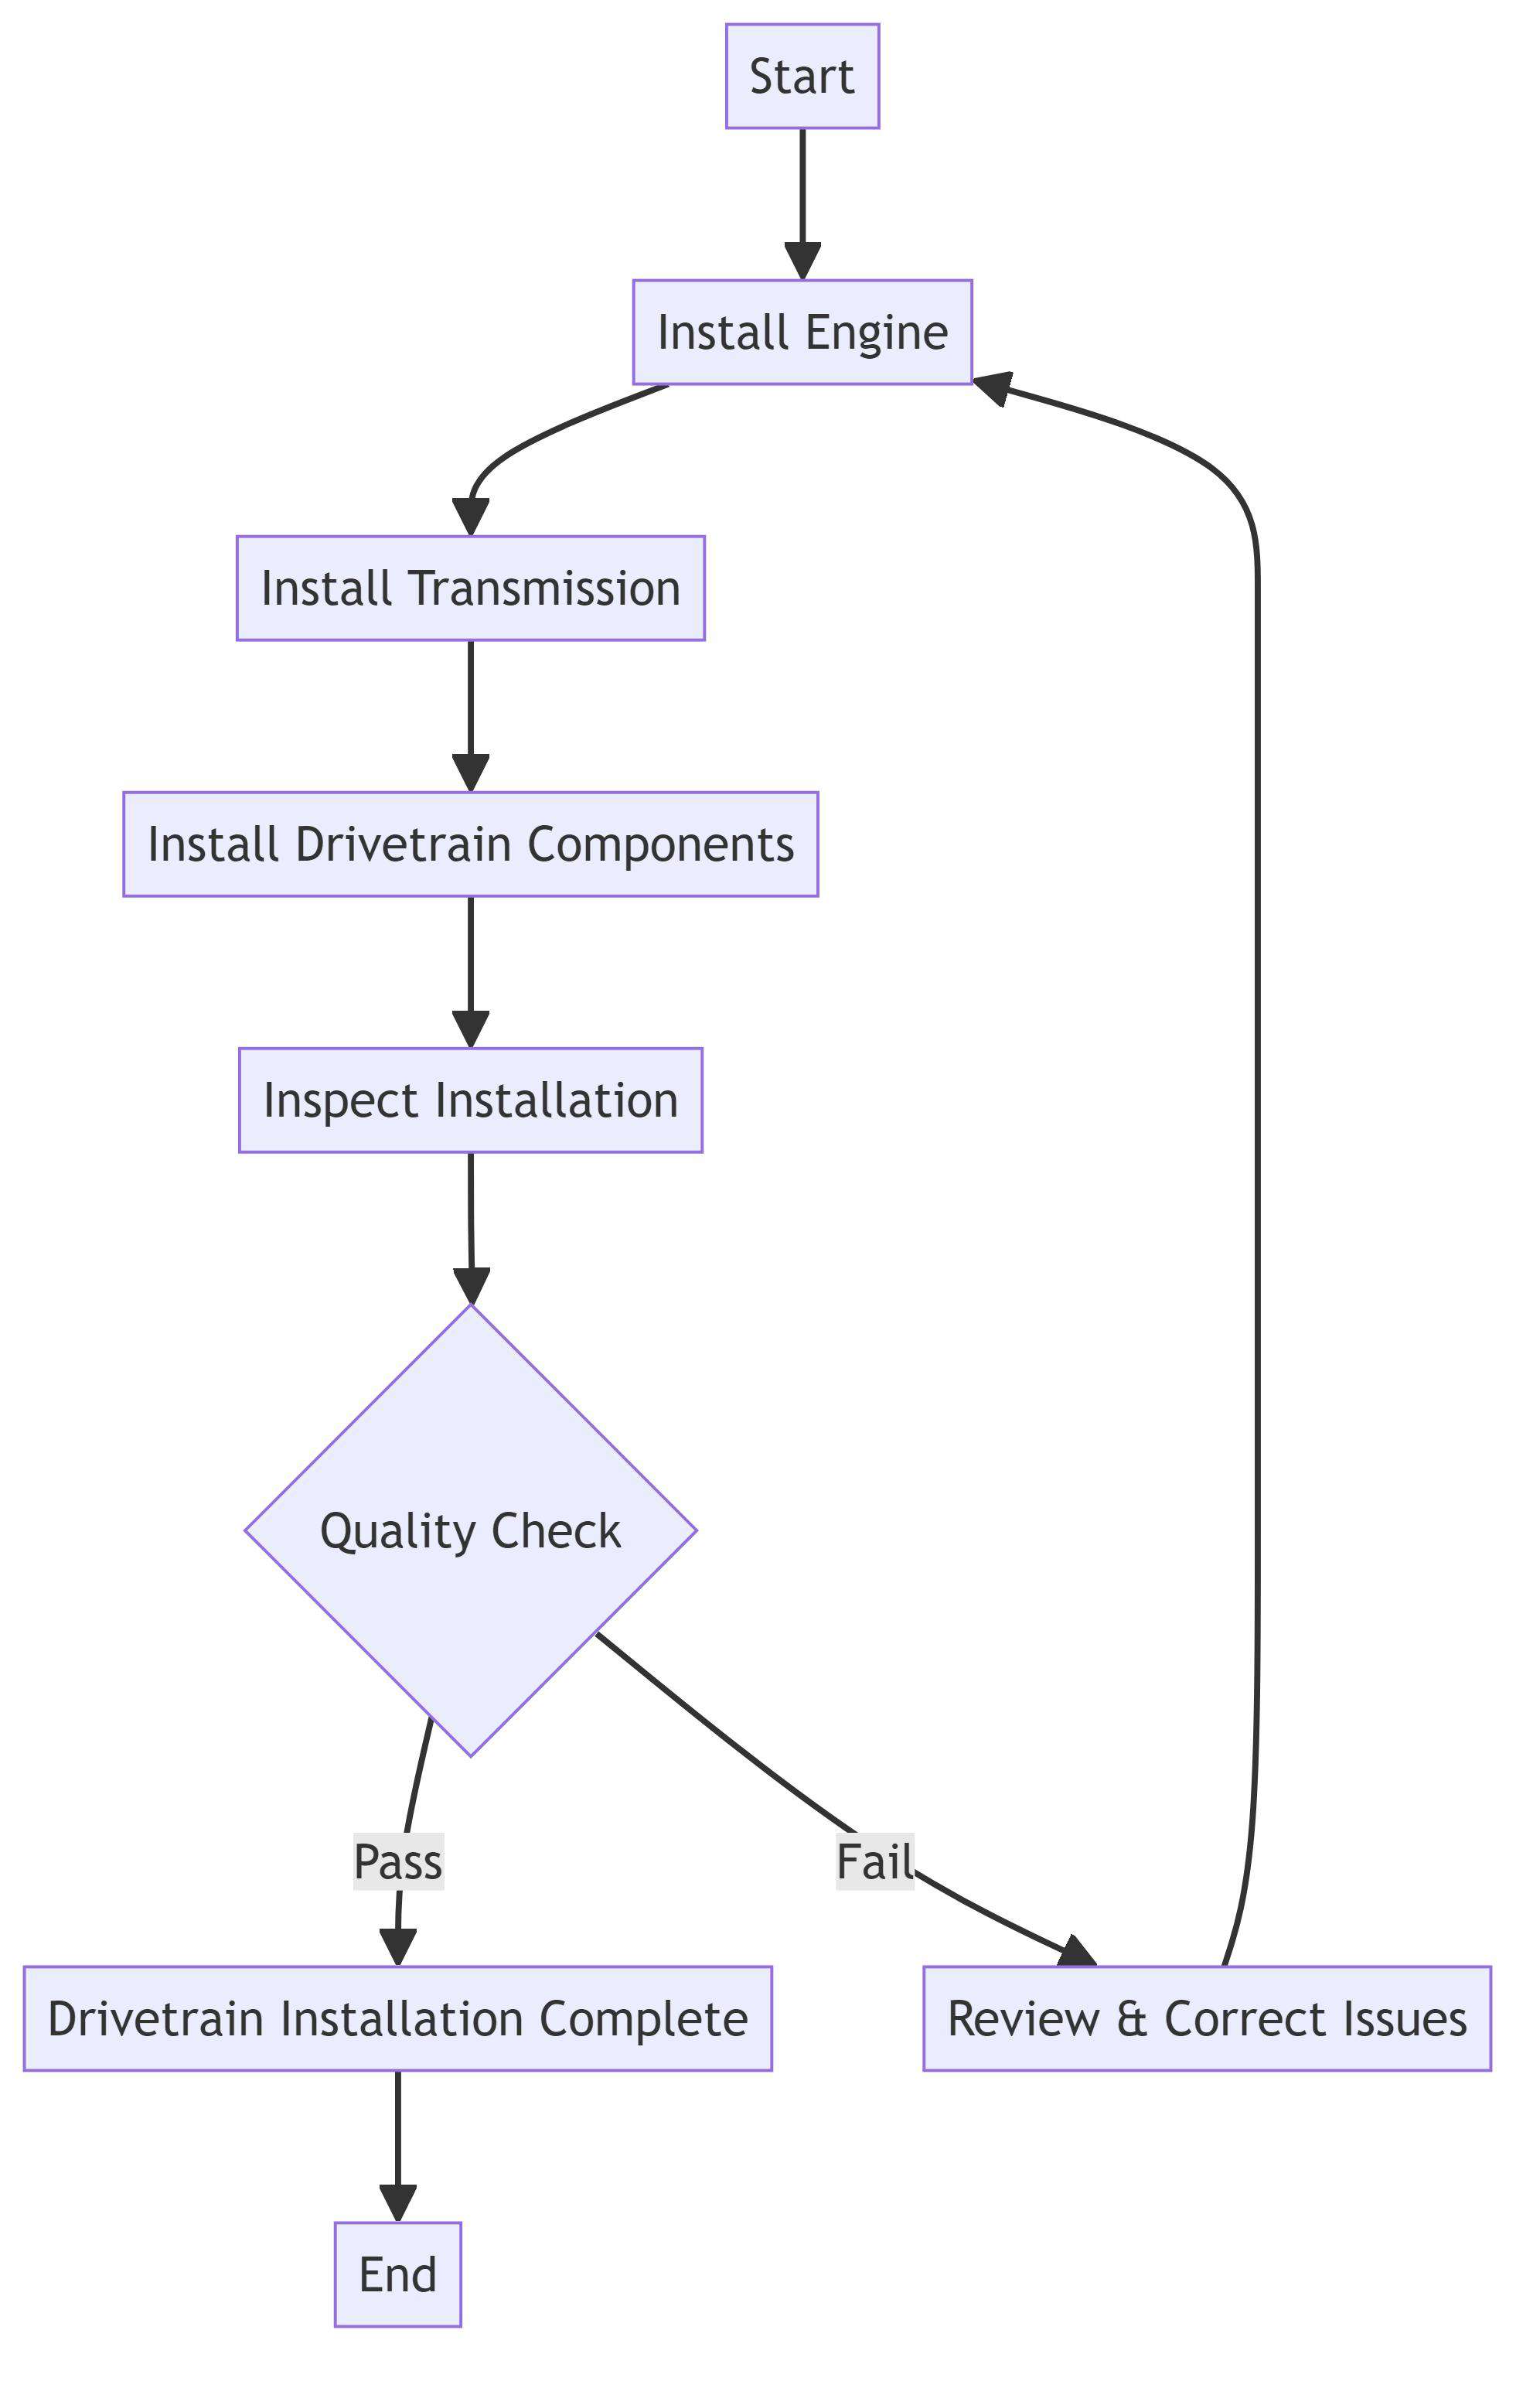

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

TARGET:
graph TD
    A[Start] --> B[Install Engine]
    B --> C[Install Transmission]
    C --> D[Install Drivetrain Components]
    D --> E[Inspect Installation]
    E --> F{Quality Check}
    F -->|Pass| G[Drivetrain Installation Complete]
    F -->|Fail| H[Review & Correct Issues]
    H --> B
    G --> I[End]


### rakitha-test-6043
source: `mermaid_flowchart_transformer` | task: `diagram_to_graph` | format: `mermaid`

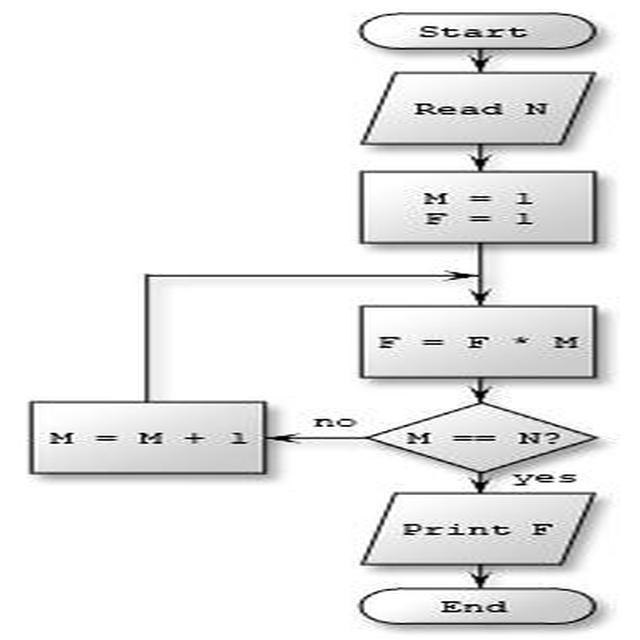

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

TARGET:
flowchart TD
    A([Start]) --> B[/Read N/]
    B --> C["M = 1 \nF = 1"]
    C --> E["F = F * M"]
    E --> F{"M == N?"}
    F -- yes --> G[/Print F/]
    G --> H([End])
    F -- no --> I["M = M + 1"]
    I --> E


In [3]:
def show_row(row: dict, max_target_chars: int = 2000) -> None:
    image = Image.open(PROCESSED_DIR / row["image_path"]).convert("RGB")
    display(Markdown(
        f"### {row['id']}\n"
        f"source: `{row['source_dataset']}` | task: `{row['task']}` | format: `{row['target_format']}`"
    ))
    display(image)
    print("INPUT PROMPT:\n" + row["input_text"])
    target = row["target_text"]
    if len(target) > max_target_chars:
        target = target[:max_target_chars] + "\n... [truncated]"
    print("\nTARGET:\n" + target)


for row in samples[:3]:
    show_row(row)


## Load The Trained Adapter

This loads the base Qwen2-VL model from `model.path` and attaches the LoRA adapter from `train.output_dir`.

In [4]:
from peft import PeftModel
from transformers import AutoProcessor, Qwen2VLForConditionalGeneration

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
ATTN_IMPL = cfg["model"].get("attn_implementation", "sdpa")

processor_source = ADAPTER_DIR if (ADAPTER_DIR / "preprocessor_config.json").exists() else BASE_MODEL
processor = AutoProcessor.from_pretrained(
    str(processor_source),
    min_pixels=cfg["model"].get("min_pixels"),
    max_pixels=cfg["model"].get("max_pixels"),
)
processor.tokenizer.padding_side = "right"

base_model = Qwen2VLForConditionalGeneration.from_pretrained(
    str(BASE_MODEL),
    torch_dtype=DTYPE,
    attn_implementation=ATTN_IMPL,
)
model = PeftModel.from_pretrained(base_model, str(ADAPTER_DIR))
model.to(DEVICE)
model.eval()

print(f"Loaded model on {DEVICE} with dtype={DTYPE}")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded model on cuda with dtype=torch.bfloat16


## Generate From One Image

### rakitha-test-6038_gaussian
source: `mermaid_flowchart_transformer` | task: `diagram_to_graph` | format: `mermaid`

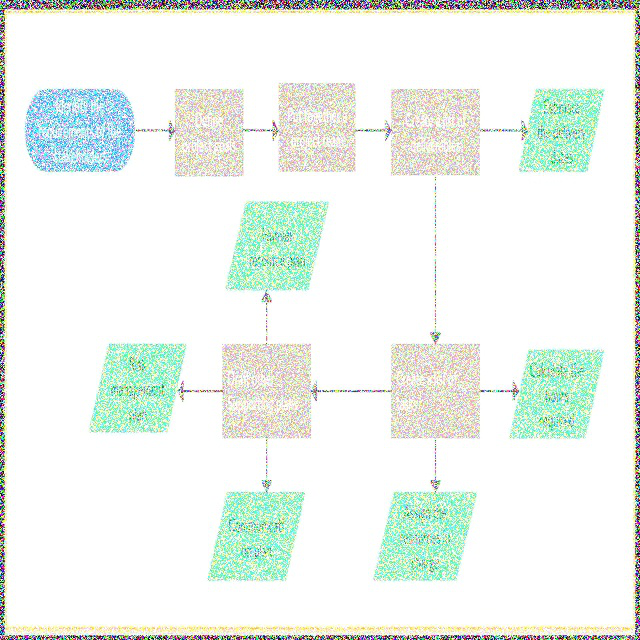

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

TARGET:
flowchart TB
    A([Identify the requirements of the stakeholders]) --> B[Define project goals]
    B --> C[Put together a project team]
    C --> E[Create a list of deliverables]
    E --> F[/Estimate the delivery dates/]
    E --> G[Create a list of tasks]
    G --> H[/Calculate the hours required/]
    G --> I[/Assign the resources in charge/]
    G --> J[Draft other Supporting plans]
    J --> D[/Human resource plan/]
    J --> K[/Communication on plan/]
    J --> L[/Risk management plan/]


### Model prediction

flowchart TD
    A([Start]) --> B[Key management plan]
    B --> C[Client certificate]
    C --> D([Generate client cert])
    D --> E([End])
    B --> F[Server certificate]
    F --> G([Generate server cert])
    G --> E


In [5]:
def move_batch_to_device(batch: dict, device: str) -> dict:
    return {key: value.to(device) if torch.is_tensor(value) else value for key, value in batch.items()}


def generate_for_row(
    row: dict,
    *,
    max_new_tokens: int = 700,
    temperature: float = 0.0,
    top_p: float = 0.9,
) -> str:
    image = Image.open(PROCESSED_DIR / row["image_path"]).convert("RGB")
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": row["input_text"]},
            ],
        }
    ]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[image], padding=True, return_tensors="pt")
    inputs = move_batch_to_device(inputs, DEVICE)

    gen_kwargs = {"max_new_tokens": max_new_tokens}
    if temperature > 0:
        gen_kwargs.update(do_sample=True, temperature=temperature, top_p=top_p)
    else:
        gen_kwargs.update(do_sample=False)

    with torch.inference_mode():
        output_ids = model.generate(**inputs, **gen_kwargs)

    new_tokens = output_ids[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()


row = samples[0]
show_row(row, max_target_chars=3000)
prediction = generate_for_row(row)

display(Markdown("### Model prediction"))
print(prediction)

## Generate For Several Samples

## Result 0: `rakitha-test-6038_gaussian`

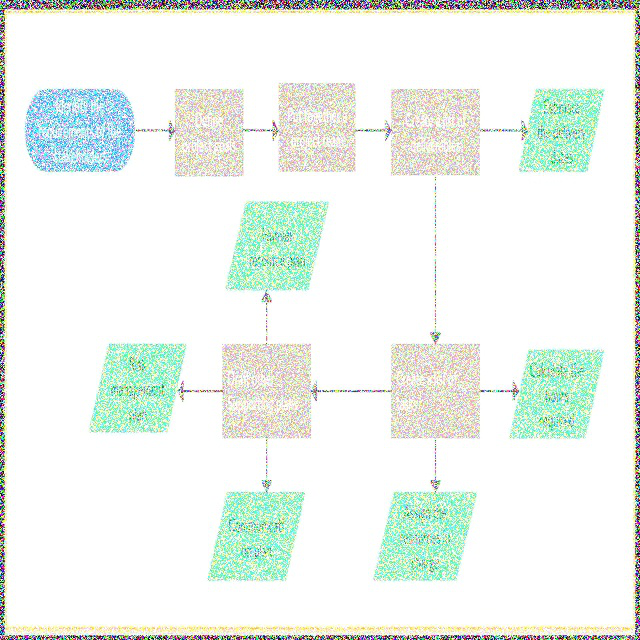

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

MODEL PREDICTION:
flowchart TD
    A([Start]) --> B[Key management plan]
    B --> C[Client certificate]
    C --> D([Generate client cert])
    D --> E([End])
    B --> F[Server certificate]
    F --> G([Generate server cert])
    G --> E

TARGET:
flowchart TB
    A([Identify the requirements of the stakeholders]) --> B[Define project goals]
    B --> C[Put together a project team]
    C --> E[Create a list of deliverables]
    E --> F[/Estimate the delivery dates/]
    E --> G[Create a list of tasks]
    G --> H[/Calculate the hours required/]
    G --> I[/Assign the resources in charge/]
    G --> J[Draft other Supporting plans]
    J --> D[/Human resource plan/]
    J --> K[/Communication on plan/]
    J --> L[/Risk management plan/]




## Result 1: `rakitha-test-1012_Automobile Manufacturing`

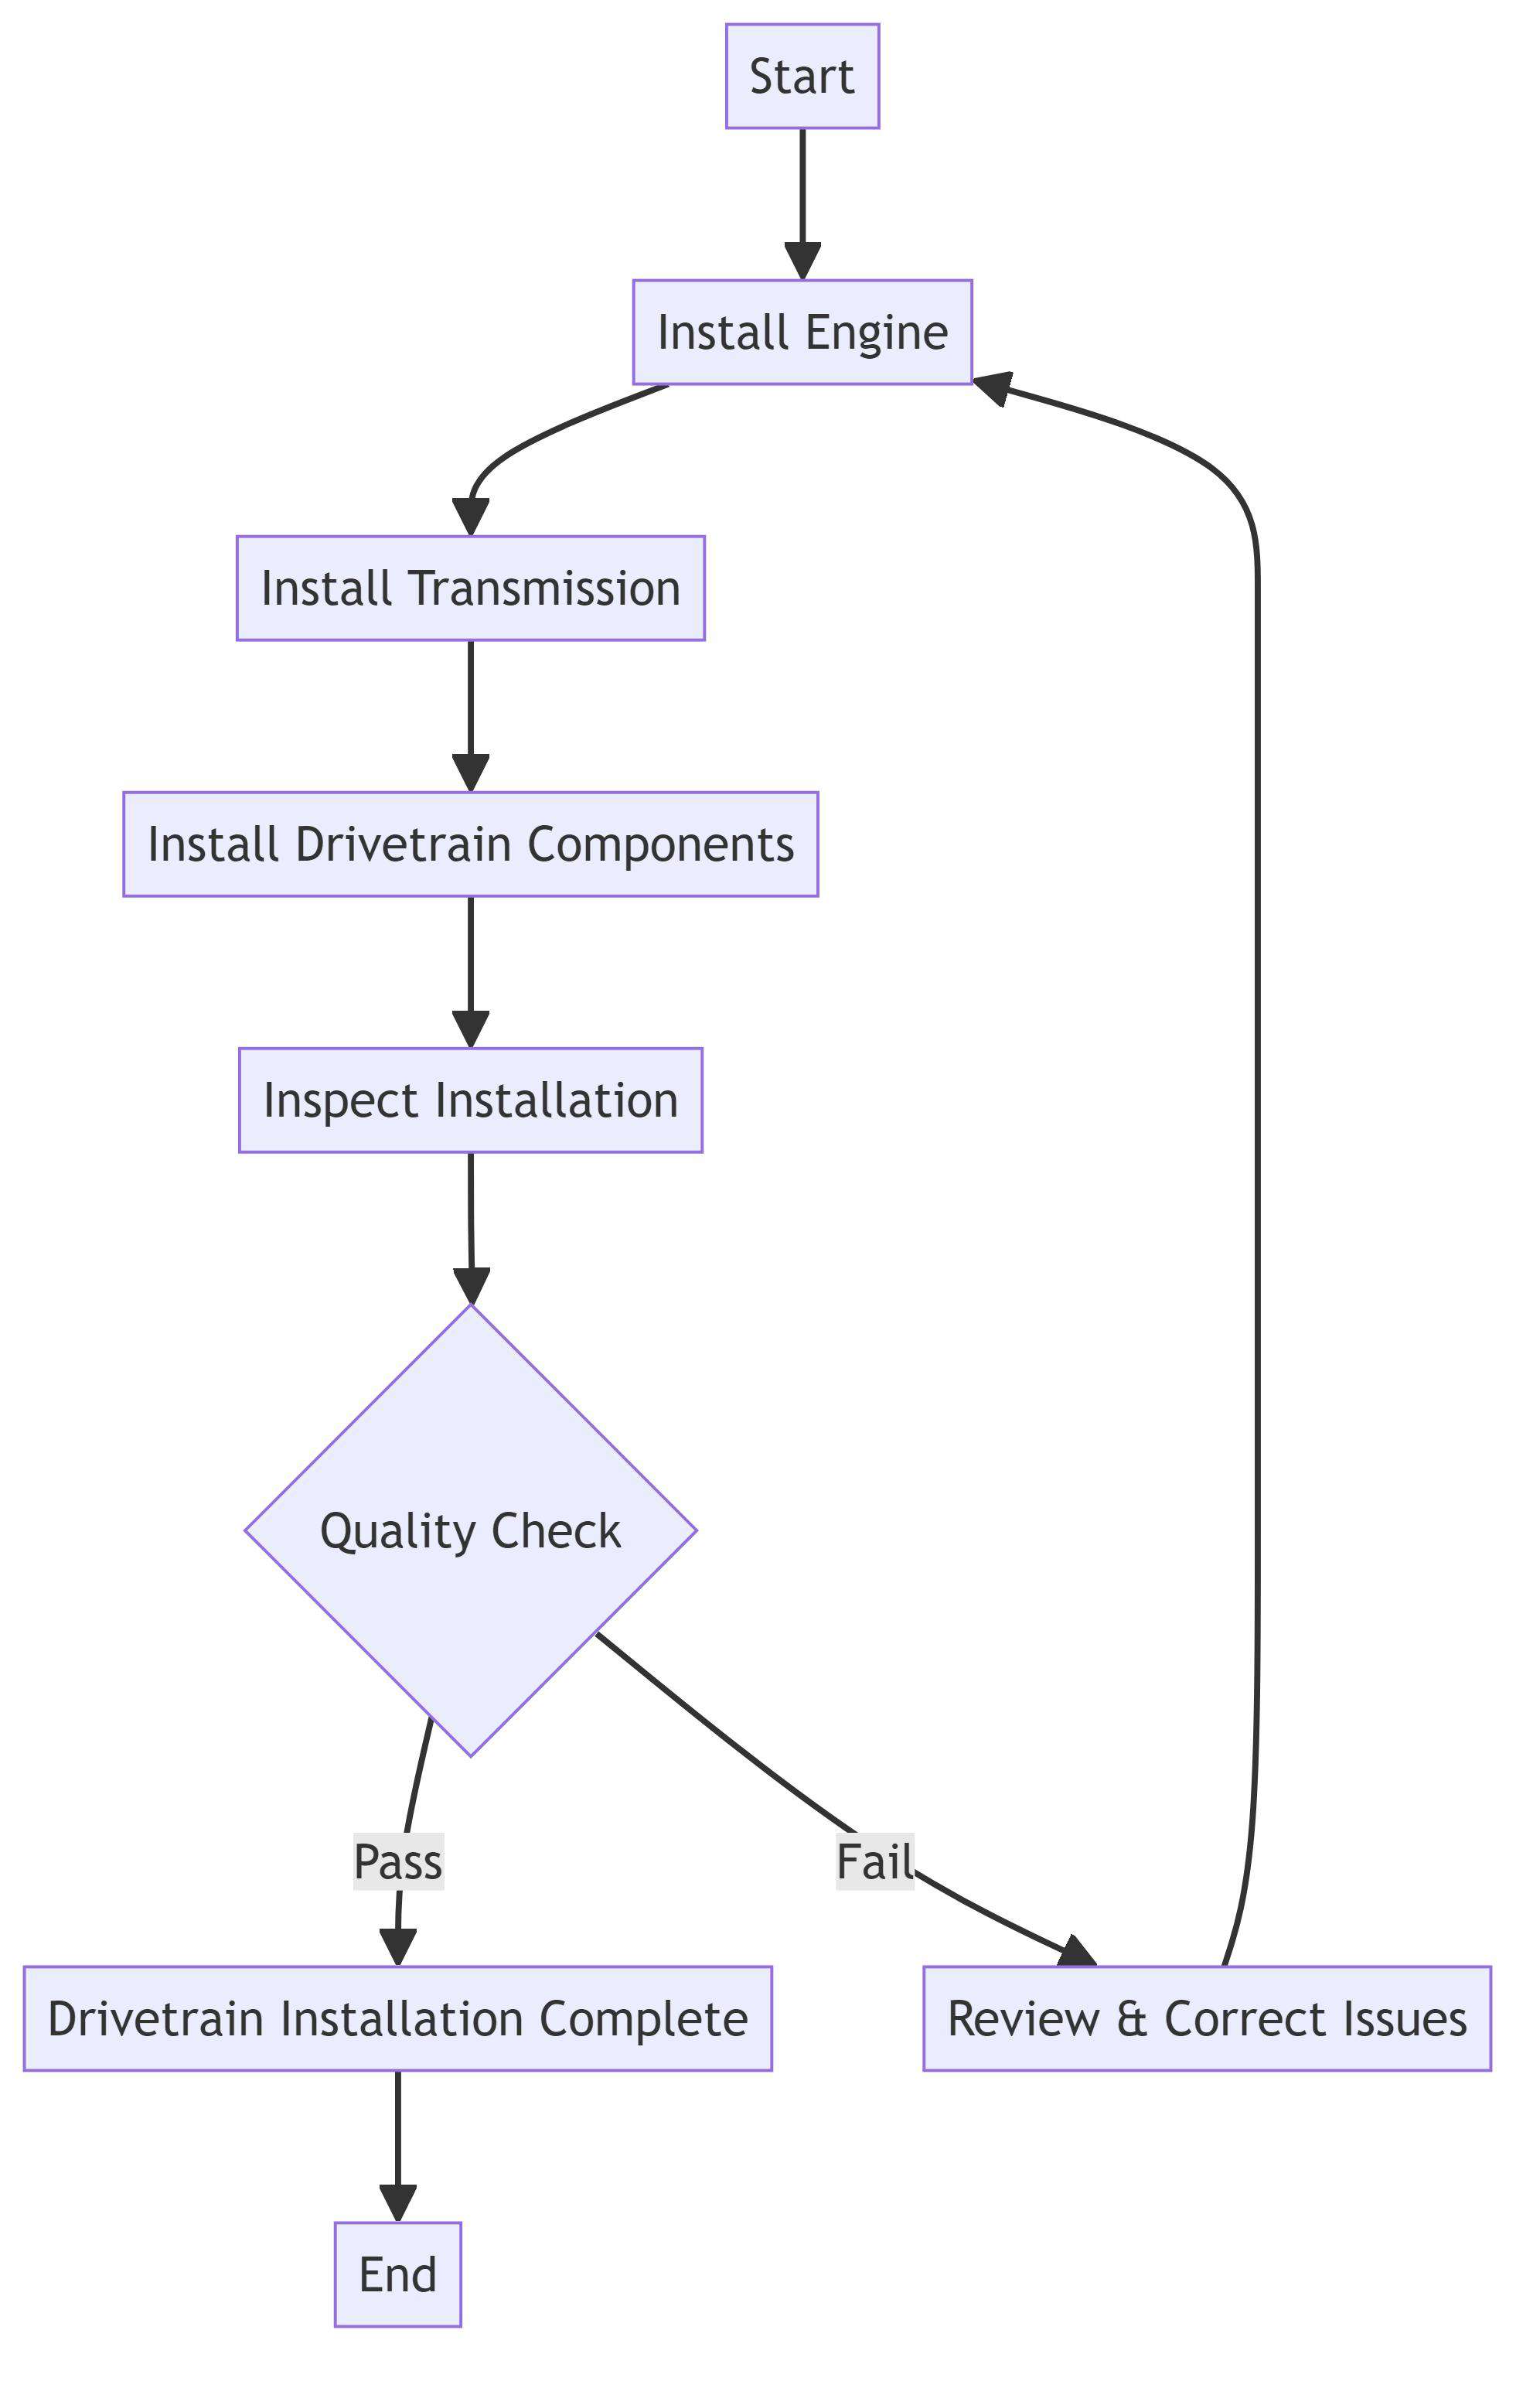

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

MODEL PREDICTION:
graph TD
    A[Start] --> B[Install Engine]
    B --> C[Install Transmission]
    C --> D[Install Drivetrain Components]
    D --> E[Inspect Installation]
    E --> F{Quality Check}
    F --> |Pass| G[Drivetrain Installation Complete]
    F --> |Fail| H[Review & Correct Issues]
    H --> F
    G --> I[End]

TARGET:
graph TD
    A[Start] --> B[Install Engine]
    B --> C[Install Transmission]
    C --> D[Install Drivetrain Components]
    D --> E[Inspect Installation]
    E --> F{Quality Check}
    F -->|Pass| G[Drivetrain Installation Complete]
    F -->|Fail| H[Review & Correct Issues]
    H --> B
    G --> I[End]




## Result 2: `rakitha-test-6043`

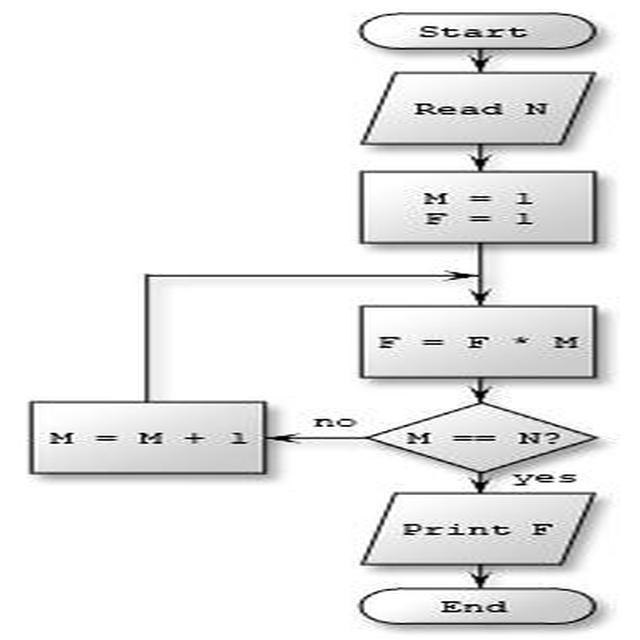

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

MODEL PREDICTION:
flowchart TD
    A([Start]) --> B[/Read N/]
    B --> C["M = 1 F = 1"]
    C --> D["F = F * M"]
    D --> E{"M == N?"}
    E -- no --> F["M = M + 1"]
    E -- yes --> G[Print F]
    G --> H([End])

TARGET:
flowchart TD
    A([Start]) --> B[/Read N/]
    B --> C["M = 1 \nF = 1"]
    C --> E["F = F * M"]
    E --> F{"M == N?"}
    F -- yes --> G[/Print F/]
    G --> H([End])
    F -- no --> I["M = M + 1"]
    I --> E




## Result 3: `rakitha-test-1048_HR`

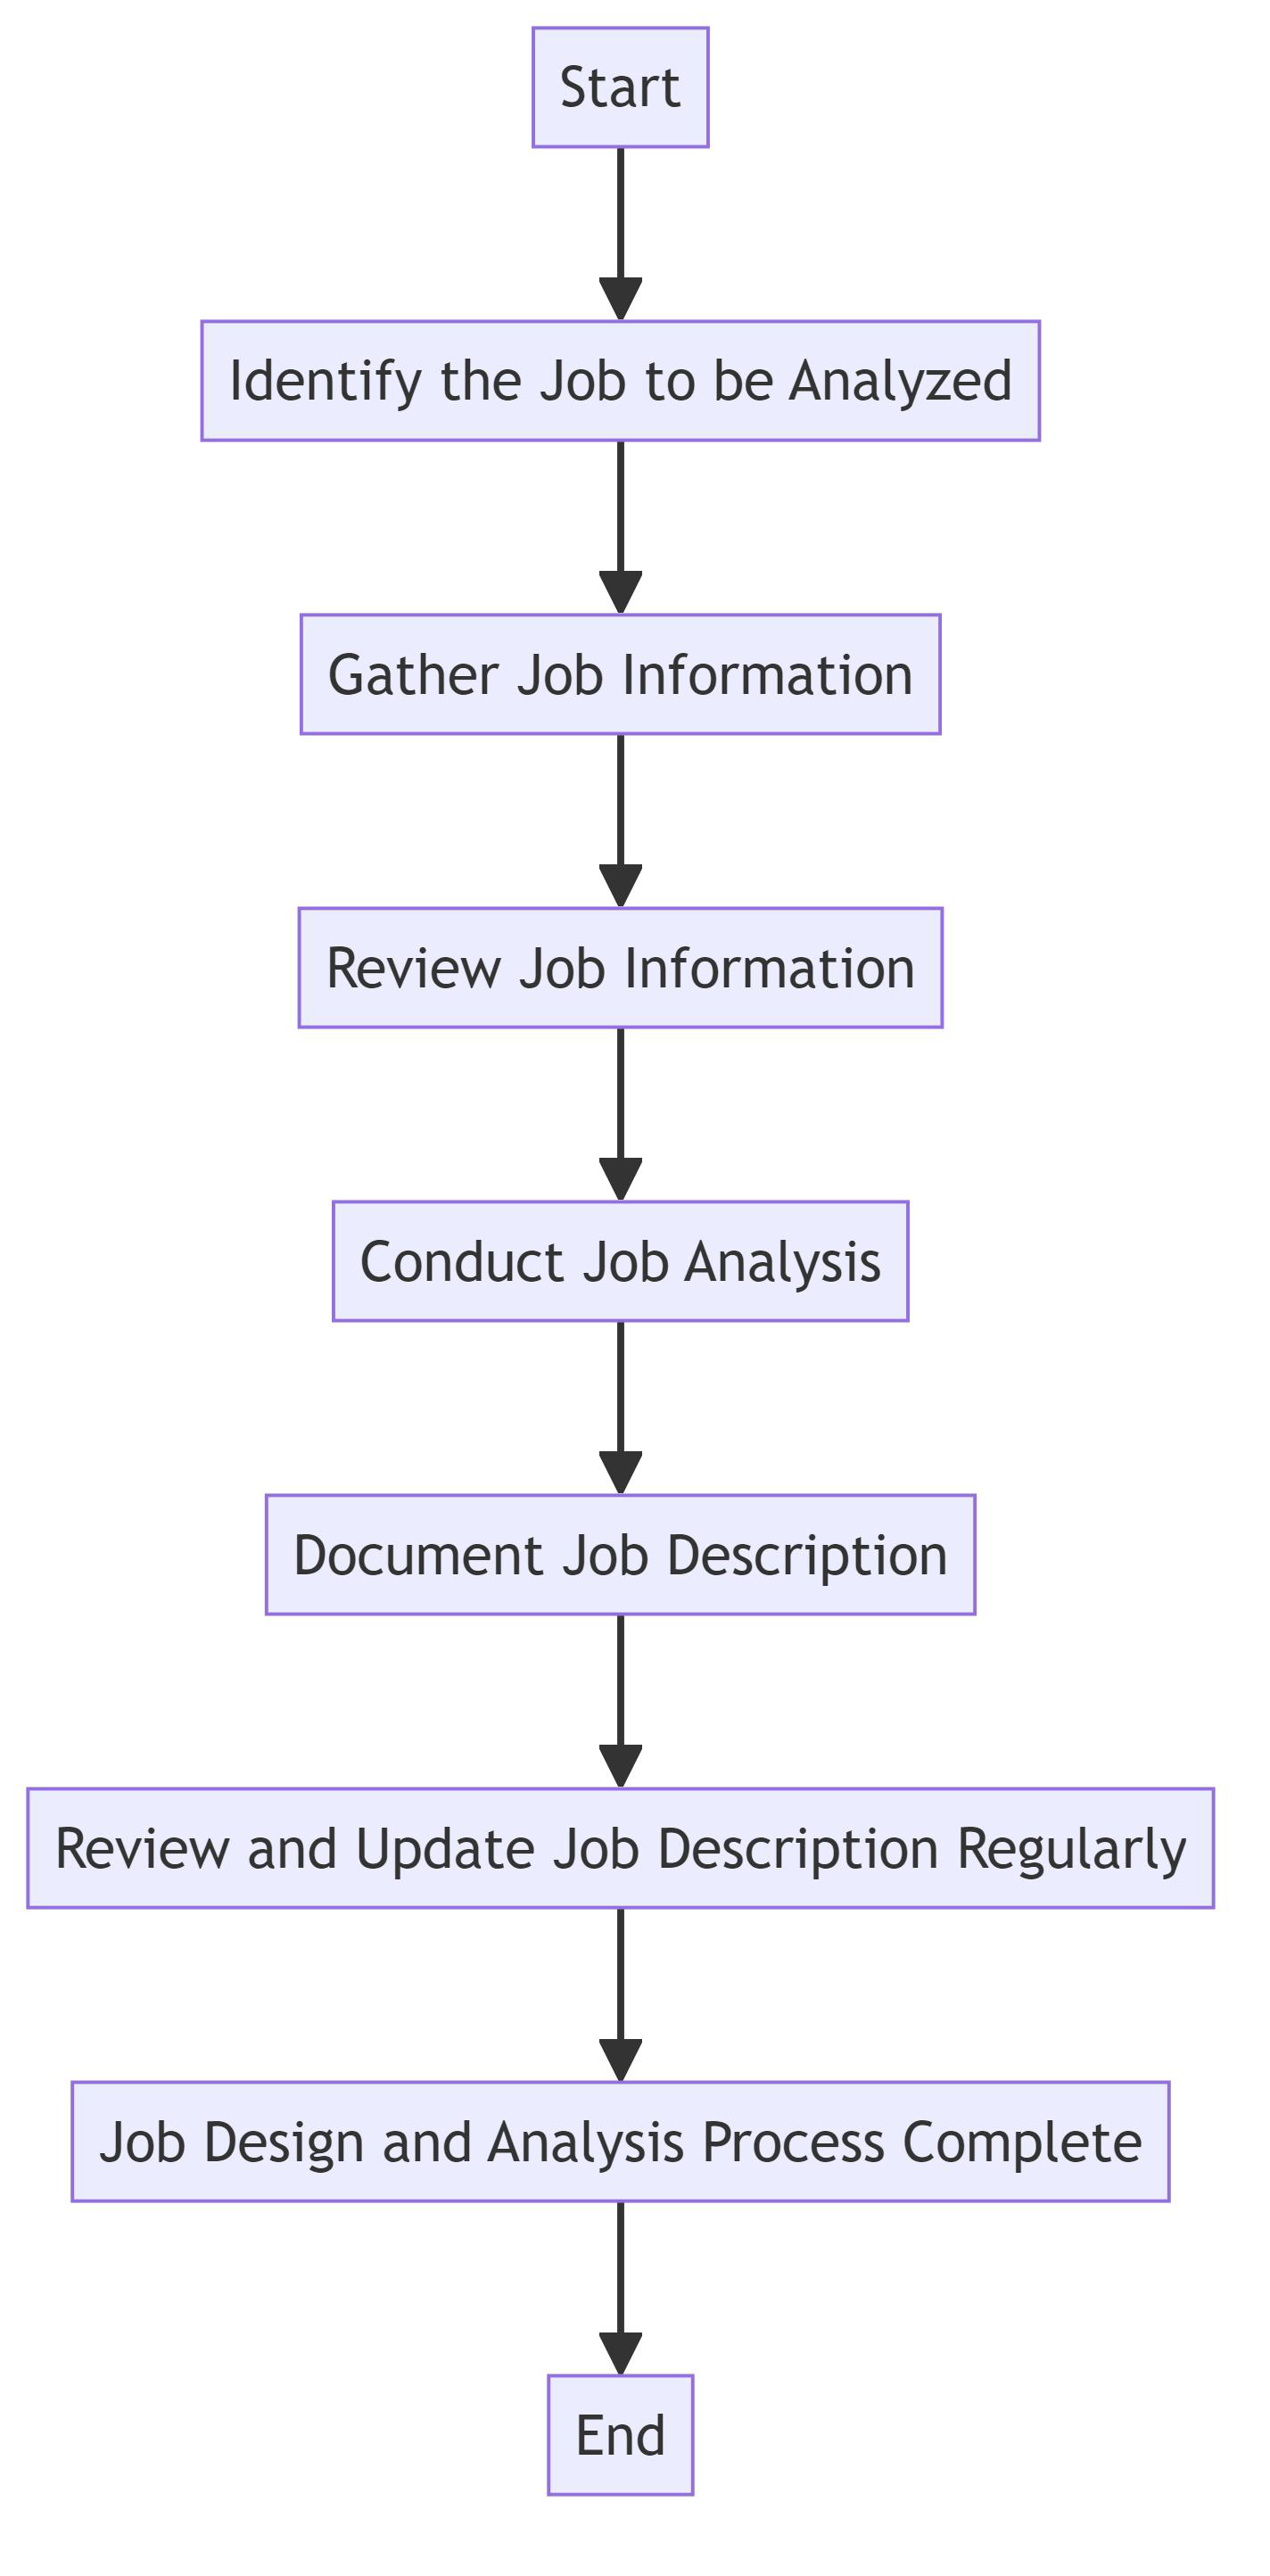

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

MODEL PREDICTION:
graph TD
    A[Start] --> B[Identify the Job to be Analyzed]
    B --> C[Gather Job Information]
    C --> D[Review Job Information]
    D --> E[Conduct Job Analysis]
    E --> F[Document Job Description]
    F --> G[Review and Update Job Description Regularly]
    G --> H[Job Design and Analysis Process Complete]
    H --> I[End]

TARGET:
graph TD
    A[Start] --> B[Identify the Job to be Analyzed]
    B --> C[Gather Job Information]
    C --> D[Review Job Information]
    D --> E[Conduct Job Analysis]
    E --> F[Document Job Description]
    F --> G[Review and Update Job Description Regularly]
    G --> H[Job Design and Analysis Process Complete]
    H --> I[End]




## Result 4: `rakitha-test-1002_Health Care`

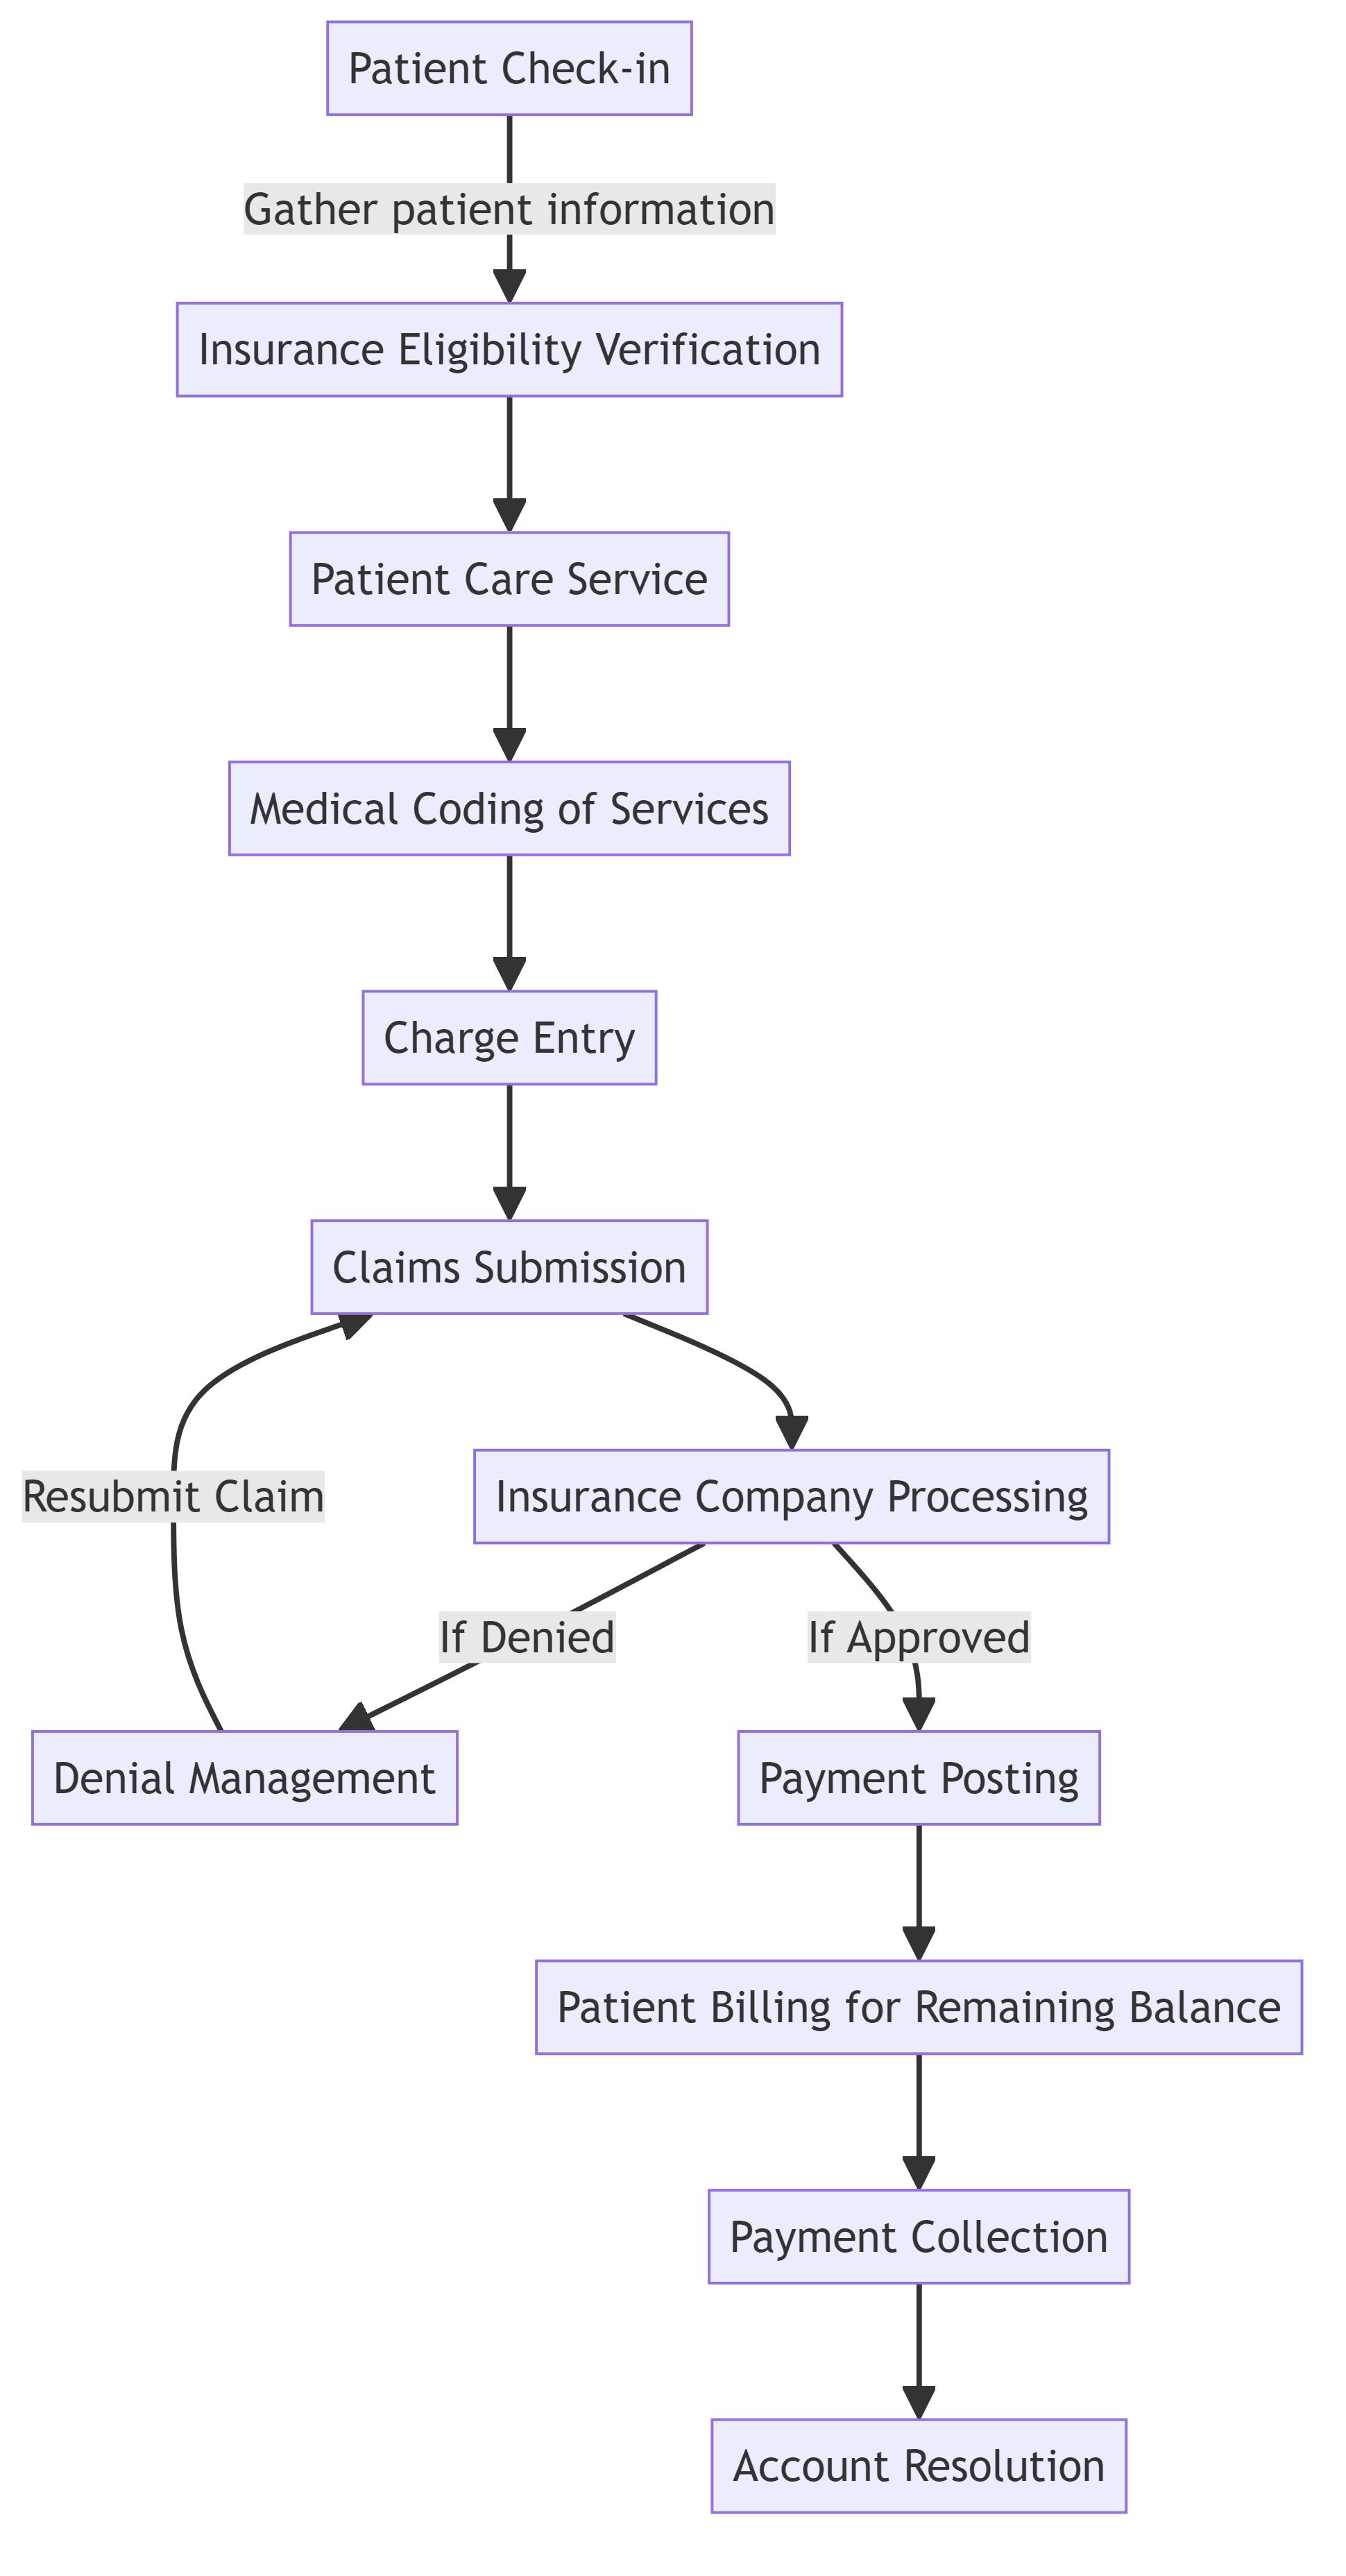

INPUT PROMPT:
Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label.

MODEL PREDICTION:
graph TD
    A[Patient Check-in] --> B[Gather patient information]
    B --> C[Insurance Eligibility Verification]
    C --> D[Patient Care Service]
    D --> E[Medical Coding of Services]
    E --> F[Charge Entry]
    F --> G[Claims Submission]
    G --> H{Resubmit Claim}
    H --> G
    H --> I[Denial Management]
    I --> J[If Denied]
    J --> F
    I --> K[If Approved]
    K --> F
    K --> L[Payment Posting]
    L --> M[Patient Billing for Remaining Balance]
    M --> N[Payment Collection]
    N --> O[Account Resolution]

TARGET:
graph TD
    A[Patient Check-in] -->|Gather patient information| B[Insurance Eligibility Verification]
    B --> C[Patient Care Service]
    C --> D[Medical Coding of Services]
    D --> E[Charge Entry]
    E --> F[Claims Submission]
    F --> G[Insurance Company Processing]
    G -->|If Denied| H[Denial Management]
    G -->|If Ap

In [6]:
results = []

for i, row in enumerate(samples):
    pred = generate_for_row(row)
    results.append({
        "id": row["id"],
        "source_dataset": row["source_dataset"],
        "task": row["task"],
        "target_format": row["target_format"],
        "image_path": row["image_path"],
        "input_text": row["input_text"],
        "target_text": row["target_text"],
        "prediction": pred,
    })

    display(Markdown(f"## Result {i}: `{row['id']}`"))
    display(Image.open(PROCESSED_DIR / row["image_path"]).convert("RGB"))
    print("INPUT PROMPT:\n" + row["input_text"])
    print("\nMODEL PREDICTION:\n" + pred)
    print("\nTARGET:\n" + row["target_text"][:3000])
    print("\n" + "=" * 100 + "\n")

## Try Your Own Image

In [ ]:
CUSTOM_IMAGE = None  # Example: Path(r"D:/path/to/diagram.png")
CUSTOM_PROMPT = "Convert this diagram into a Mermaid graph. Preserve every node, edge, direction, and label."

if CUSTOM_IMAGE is None:
    print("Set CUSTOM_IMAGE to a local image path, then re-run this cell.")
else:
    custom_image = Image.open(CUSTOM_IMAGE).convert("RGB")
    display(custom_image)
    custom_row = {
        "image_path": str(CUSTOM_IMAGE),
        "input_text": CUSTOM_PROMPT,
    }

    messages = [{
        "role": "user",
        "content": [{"type": "image"}, {"type": "text", "text": CUSTOM_PROMPT}],
    }]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[custom_image], padding=True, return_tensors="pt")
    inputs = move_batch_to_device(inputs, DEVICE)
    with torch.inference_mode():
        output_ids = model.generate(**inputs, max_new_tokens=700, do_sample=False)
    new_tokens = output_ids[:, inputs["input_ids"].shape[1]:]
    print(processor.batch_decode(new_tokens, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip())


## Save Generated Results

In [7]:
if "results" in globals() and results:
    output_path = PROJECT_ROOT / "demo_outputs.jsonl"
    with output_path.open("w", encoding="utf-8") as fh:
        for item in results:
            fh.write(json.dumps(item, ensure_ascii=False) + "\n")
    print(f"Saved {len(results)} rows to {output_path}")
else:
    print("Run the multi-sample generation cell first.")

Saved 5 rows to D:\src\Diagram_extraction\demo_outputs.jsonl


Short version: the run is probably data-limited, not just hyperparameter-limited.

In [config.yaml](d:/src/Diagram_extraction/src/train/config.yaml:15), `train_samples: 8000` means **8,000 sampled training rows**, not 8,000 unique images. The trainer intentionally samples a balanced epoch instead of using the raw dataset because the processed data is extremely QA-heavy: about **248k QA rows**, but only **1,198 total diagram-to-graph rows**.

Your actual train run used:

```text
8000 rows total
4400 diagram_to_graph
1600 diagram_to_code
1600 diagram_qa
400 diagram_caption
```

But the train split only has **966 usable image-to-graph rows**. So those 4,400 graph rows are partly repeated/up-sampled by [train_qwen.py](d:/src/Diagram_extraction/src/train/train_qwen.py:99). That helps focus the task, but it limits real visual diversity.

Why accuracy feels low:

- You trained only **1 epoch**.
- Only **0.829%** of model params are trainable LoRA params.
- Vision tower is frozen; LoRA targets only language modules.
- Graph data is small: **966 usable training graph images**.
- Eval is tiny: only **26 usable validation graph rows**, despite `eval_samples: 200`.
- `max_seq_len: 2048` can truncate long TikZ/SVG/code targets.
- The metric is `eval_loss`, not real diagram accuracy. It does not check graph/node/edge correctness.

Why rows/images were skipped:

- Trainer filters rows whose `image_path` is missing or whose image file does not exist.
- Formatted stats show missing images:
  - `diagramgen`: 35 missing
  - `mermaid_flowchart_transformer`: 2 missing
  - `vgqa`: 22 missing
- VGQA images are rendered from code; failures can come from missing `dot`, `pdflatex`, `pdftoppm`, `cairosvg`, render timeouts, or invalid source code.
- `mermaid_50k` is currently skipped if the gated `mermaid_50k.jsonl` is not downloaded.

Best ways to improve it:

1. Add more real graph data, especially `mermaid_50k` or other image-to-Mermaid/image-to-DOT datasets.
2. Fix rendering tools and re-format data so fewer rows have missing images.
3. Increase epochs to `2-3`, but only after improving graph data.
4. Raise LoRA capacity, e.g. `r: 32`, if VRAM allows.
5. Use a larger eval set; 26 rows is too small to trust.
6. Add graph-level evaluation: parse generated Mermaid/DOT/JSON and compare nodes/edges, not just token loss.
7. Consider reducing mixed objectives if final goal is graph extraction: more `diagram_to_graph`, less QA/code/caption.

So yes, use “all 8k” is already happening as rows, but the stronger fix is: get more **unique usable graph images**, then train longer and evaluate with graph metrics.